# HW4 - Design of Experiments

The goal is to use the functions written above to model and analyze the circuit-board.csv dataset.
Problem Formulation:
A router is used to cut locating notches circuit boards but vibrations on the surface of such boards are considered to be a major factor in dimensional variations(errors). Two factors have been identified:
1. Bit Size (A)
2. Drill RPM/Cutting Speed (B)
The objective is to minimize mean vibrations with from the given data.
There are 4 modification combinations and 4 board sizes per combination, which gives a total of 16 observations. 

In [ ]:
# YOUR CODE HERE - you can create as many additional Markdown or Code cells as needed
# Suman's code
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
import doe
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.precision', 5)


Python: 3.12.3


Now, let's import the data and initialize labels

In [ ]:
data_path = Path('circuit-board.csv')
if not data_path.exists():
    raise FileNotFoundError('Wrong folder path, include the data file here')
raw = pd.read_csv(data_path, encoding='utf-8-sig')
responses = raw.to_numpy(dtype=float)
n_replicates = responses.shape[1]
assert responses.shape == (4, 4), 'Expected four treatments and four boards per treatment.'
assert np.isfinite(responses).all()
labels = ['(1): A− B−', 'a: A+ B−', 'b: A− B+', 'ab: A+ B+']
A = np.array([-1, 1, -1, 1])
B = np.array([-1, -1, 1, 1])

Let's organize the data and generate the grand mean

In [4]:
wide = pd.DataFrame(responses, index=labels,
                    columns=[f'Replicate {i+1}' for i in range(n_replicates)])
display(wide)
long = pd.DataFrame({'treatment': np.repeat(labels, n_replicates),
                     'A': np.repeat(A, n_replicates),
                     'B': np.repeat(B, n_replicates),
                     'replicate': np.tile(np.arange(1, n_replicates+1), 4),
                     'vibration': responses.ravel()})
means = responses.mean(axis=1)
summary = pd.DataFrame({'bit size (in.)': ['1/16', '1/8', '1/16', '1/8'],
                        'speed (rpm)': [40, 40, 90, 90],
                        'n': n_replicates, 'mean': means,
                        'sample SD': responses.std(axis=1, ddof=1),
                        'minimum': responses.min(axis=1),
                        'maximum': responses.max(axis=1)}, index=labels)
display(summary)
print(f'Grand mean = {responses.mean():.5f}')

,Replicate 1,Replicate 2,Replicate 3,Replicate 4
(1): A− B−,18.2,18.9,12.9,14.4
a: A+ B−,27.2,24.0,22.4,22.5
b: A− B+,15.9,14.5,15.1,14.2
ab: A+ B+,41.0,43.9,36.3,39.9


,bit size (in.),speed (rpm),n,mean,sample SD,minimum,maximum
(1): A− B−,1/16,40,4,16.100,2.90861,12.9,18.9
a: A+ B−,1/8,40,4,24.025,2.23961,22.4,27.2
b: A− B+,1/16,90,4,14.925,0.75000,14.2,15.9
ab: A+ B+,1/8,90,4,40.275,3.14152,36.3,43.9


Grand mean = 23.83125


Now, let us use the effects function defined previously to obtain main and interaction effects and see how the average vibration changes when we change experiment settings. 

,effect,absolute magnitude
A,16.6375,16.6375
B,7.5375,7.5375
AB,8.7125,8.7125


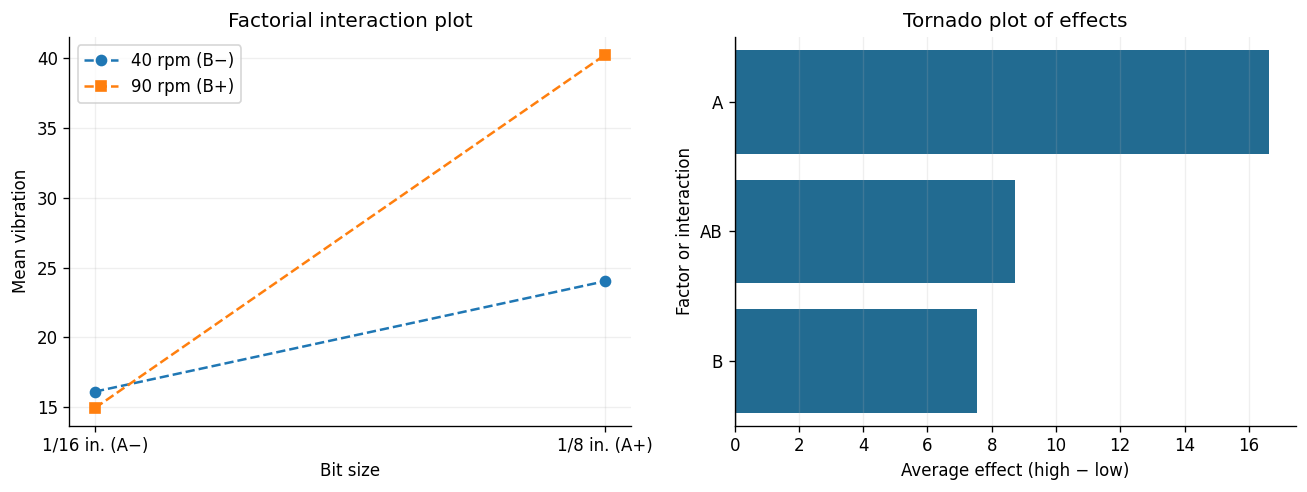

,conditional high-minus-low effect
Bit-size effect at 40 rpm,7.925
Bit-size effect at 90 rpm,25.350
Speed effect with 1/16-in. bit,-1.175
Speed effect with 1/8-in. bit,16.250


In [5]:
effect_values = doe.effects(responses, n_replicates)
effect_table = pd.DataFrame({'effect': effect_values,
                              'absolute magnitude': np.abs(effect_values)},
                             index=['A', 'B', 'AB'])
display(effect_table)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
plt.sca(axes[0])
lines = doe.plot_effects(responses, n_replicates)
lines[0].set_label('40 rpm (B−)')
lines[1].set_label('90 rpm (B+)')
axes[0].set_xticks([-1, 1], ['1/16 in. (A−)', '1/8 in. (A+)'])
axes[0].set_xlabel('Bit size')
axes[0].set_ylabel('Mean vibration')
axes[0].legend()
plt.sca(axes[1])
doe.plot_tornado(responses, n_replicates)
fig.tight_layout()
plt.show()

simple_effects = pd.Series({
    'Bit-size effect at 40 rpm': means[1]-means[0],
    'Bit-size effect at 90 rpm': means[3]-means[2],
    'Speed effect with 1/16-in. bit': means[2]-means[0],
    'Speed effect with 1/8-in. bit': means[3]-means[1]})
display(simple_effects.to_frame('conditional high-minus-low effect'))

Analysis of main and interaction effects:
1. Bit Size (A): Averaged equally over both speeds, going from 1/16 to 1/8 inches increases vibration by 16.6375 units for the large bit and decreases vibration by -1.175 units for the small bit. This is the largest factorial effect. However, the increase is 7.925 at 40 rpm and 25.350 at 90 rpm, which shows that increasing the bit size induces more vibration regardless of speed.
2. Speed (B): For both the bit sizes, moving from 40 to 90 rpm increases vibration by 7.5375 units. With the large bit, increasing RPM significantly increases the vibration compared to the smaller bit, but the larger bit does not increase vibration by the same amount at both speeds.
3. Interaction effects: The larger bit produces more vibrations at higher RPMs compared to the smaller bit. The change in the bit-size effect is 25.350-7.925=17.425, which is 2 times the effect of AB. Equivalently, the speed effect changes by 16.250-(-1.175)=17.425 across bit sizes. The change in one factor’s effect across the other factor’s levels is twice the interaction effect, implying that the effect of changing bit size depends on the cutting speed.


We now fit a model of the form
y=b_0+b_1*x_A+b_2*x_B+b_3*x_A*x_B for the ANOVA test

In [6]:
y = long['vibration'].to_numpy()
X = np.column_stack([np.ones(len(y)), long['A'], long['B'], long['A']*long['B']])
beta = np.linalg.lstsq(X, y, rcond=None)[0]
fitted = X @ beta
residuals = y - fitted
N = len(y)
df_error = N - X.shape[1]
SSE = residuals @ residuals
MSE = SSE / df_error
sigma_hat = np.sqrt(MSE)
tcrit = stats.t.ppf(0.975, df_error)
cov_beta = MSE * np.linalg.inv(X.T @ X)
se_beta = np.sqrt(np.diag(cov_beta))
coef_table = pd.DataFrame({'estimate': beta, 'SE': se_beta,
                           '95% CI lower': beta-tcrit*se_beta,
                           '95% CI upper': beta+tcrit*se_beta},
                          index=['Intercept', 'A', 'B', 'AB'])
display(coef_table)
assert np.allclose(beta[1:], effect_values/2)
assert np.allclose(fitted.reshape(4, n_replicates).mean(axis=1), means)
print(f'Fitted model: y_hat = {beta[0]:.5f} + {beta[1]:.5f} x_A '
      f'+ {beta[2]:.5f} x_B + {beta[3]:.5f} x_A x_B')
print(f'Residual standard deviation = {sigma_hat:.5f}')


,estimate,SE,95% CI lower,95% CI upper
Intercept,23.83125,0.61119,22.49958,25.16292
A,8.31875,0.61119,6.98708,9.65042
B,3.76875,0.61119,2.43708,5.10042
AB,4.35625,0.61119,3.02458,5.68792


Fitted model: y_hat = 23.83125 + 8.31875 x_A + 3.76875 x_B + 4.35625 x_A x_B
Residual standard deviation = 2.44476


Now let's perform the ANOVA test

In [7]:
SS_terms = n_replicates * effect_values**2
SST = np.sum((y-y.mean())**2)
F_terms = SS_terms / MSE
p_terms = stats.f.sf(F_terms, 1, df_error)
anova = pd.DataFrame({
    'SS': [*SS_terms, SSE, SST],
    'df': [1, 1, 1, df_error, N-1],
    'MS': [*SS_terms, MSE, np.nan],
    'F': [*F_terms, np.nan, np.nan],
    'p-value': [*p_terms, np.nan, np.nan]},
    index=['A: bit size', 'B: speed', 'A × B', 'Error', 'Total'])
display(anova.style.format({'SS':'{:.6f}', 'MS':'{:.6f}', 'F':'{:.4f}',
                            'p-value':'{:.3e}'}, na_rep='—'))
assert np.isclose(SS_terms.sum()+SSE, SST)
R2 = 1-SSE/SST
R2_adj = 1-MSE/(SST/(N-1))
print(f'R² = {R2:.6f}; adjusted R² = {R2_adj:.6f}')
display(pd.Series(100*SS_terms/SST, index=['A', 'B', 'AB'],
                  name='Percentage of corrected total SS').to_frame())
se_effect = np.sqrt(MSE/n_replicates)
effect_table['SE'] = se_effect
effect_table['95% CI lower'] = effect_values-tcrit*se_effect
effect_table['95% CI upper'] = effect_values+tcrit*se_effect
display(effect_table)

,SS,df,MS,F,p-value
A: bit size,1107.225625,1,1107.225625,185.2516,1.175e-08
B: speed,227.255625,1,227.255625,38.0225,4.826e-05
A × B,303.630625,1,303.630625,50.8009,1.201e-05
Error,71.722500,12,5.976875,—,—
Total,1709.834375,15,—,—,—


R² = 0.958053; adjusted R² = 0.947566


,Percentage of corrected total SS
A,64.75631
B,13.29109
AB,17.75790


,effect,absolute magnitude,SE,95% CI lower,95% CI upper
A,16.6375,16.6375,1.22238,13.97416,19.30084
B,7.5375,7.5375,1.22238,4.87416,10.20084
AB,8.7125,8.7125,1.22238,6.04916,11.37584


Analysis of the ANOVA test:
From the results, the error sum of squares is 71.7225, the pooled error mean square is 5.976875 and the estimated board-to-board residual standard deviation is approximately 2.445 units. The bit-size sum of squares is 1107.225625, the speed sum of squares is 227.255625, and the interaction sum of squares is 303.630625. All three tests reject their respective null hypotheses at alpha=0.05: the p-values are approximately 1.17*10^{-8}, 4.83*10^{-5}, and 1.20*10^{-5}. This shows that we need the individual board measurements to find how much vibration varies even when the machine settings stay the same and that variation provides the baseline for the ANOVA tests. The 95% confidence intervals have common half-width 2.6633 and from the R^2 and adjusted R^2 values, 95.81% of the observed variation in vibration is explained by differences among the four operating conditions while the remaining 4.19% is variation among boards tested under similar conditions, but doesn't mean that predictions are 95.81% accurate.

Recommendation for daily use:
I think using the 1/16-inch bit at 90 RPM because this combination produces the lowest vibration of 14.925 units. The smaller bit produces much lower overall vibrations at the given speeds compared to the larger bit which increases induced vibration significantly. With the smaller bit increasing speed reduced mean vibration by only 1.175 units, and the 95% confidence interval for this change, [−4.942, 2.592], includes zero, implying that the magnitude of vibration may be considered very small. I have chosen 90 RPM because I believe it would be easier for the drill to cut through the plastic on the boards, but 40 RPM may also be used whenever necessary.